# CardioIA Fase 4 | Ir Além 1: fairness da CNN do zero

A rede erra igual para homens e mulheres? E para jovens e idosos?

Usa as previsões do conjunto de teste salvas pela Parte 2a.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEMENTE = 42
REPETICOES_DO_BOOTSTRAP = 2000

esta_no_colab = Path("/content").exists()
PASTA_DADOS = Path("/content/dados") if esta_no_colab else Path("../dados")

selecao = pd.read_csv(PASTA_DADOS / "processados" / "selecao.csv")
previsoes = pd.read_csv(PASTA_DADOS / "previsoes_teste.csv")

selecao["faixa_etaria"] = pd.cut(selecao["idade"], bins=[17, 39, 59, 100], labels=["18-39", "40-59", "60+"])
teste = previsoes.merge(selecao, on="arquivo", validate="one_to_one")
assert len(teste) == len(previsoes)

## 1. O dataset representa todo mundo?

In [2]:
print("Distribuição por sexo (%), dataset selecionado:")
print((100 * pd.crosstab(selecao["classe"], selecao["sexo"], normalize="index")).round(1))
print("\nDistribuição por faixa etária (%), dataset selecionado:")
print((100 * pd.crosstab(selecao["classe"], selecao["faixa_etaria"], normalize="index")).round(1))

Distribuição por sexo (%), dataset selecionado:
sexo              F     M
classe                   
cardiomegalia  56.8  43.2
sem_achado     46.6  53.4

Distribuição por faixa etária (%), dataset selecionado:
faixa_etaria   18-39  40-59   60+
classe                           
cardiomegalia   24.6   42.3  33.1
sem_achado      34.2   45.2  20.6


## 2. Métricas por grupo

- **Recall:** dos doentes, quantos a rede encontrou (igualdade de oportunidade).
- **Falso positivo:** dos saudáveis, quantos ela marcou como doentes.
- **Marcados como doentes:** quanto do grupo recebeu o alerta (paridade demográfica).

In [3]:
def metricas_do_grupo(grupo):
    doentes = grupo[grupo["verdadeira"] == 1]
    saudaveis = grupo[grupo["verdadeira"] == 0]
    return pd.Series(
        {
            "doentes": len(doentes),
            "saudaveis": len(saudaveis),
            "acuracia": (grupo["verdadeira"] == grupo["prevista"]).mean(),
            "recall": doentes["prevista"].mean(),
            "falso_positivo": saudaveis["prevista"].mean(),
            "marcados_como_doentes": grupo["prevista"].mean(),
        }
    )


def metricas_por(coluna):
    return pd.DataFrame({nome: metricas_do_grupo(grupo) for nome, grupo in teste.groupby(coluna, observed=True)}).T


por_sexo = metricas_por("sexo")
por_idade = metricas_por("faixa_etaria")
tabela = pd.concat({"sexo": por_sexo, "idade": por_idade}).round(3)
tabela.to_csv("metricas_por_grupo.csv")
print(tabela.to_string())

             doentes  saudaveis  acuracia  recall  falso_positivo  marcados_como_doentes
sexo  F         91.0       80.0     0.643   0.659           0.375                  0.526
      M         77.0       88.0     0.715   0.545           0.136                  0.327
idade 18-39     37.0       54.0     0.725   0.568           0.167                  0.330
      40-59     78.0       87.0     0.685   0.628           0.264                  0.436
      60+       53.0       27.0     0.612   0.604           0.370                  0.525


## 3. A diferença é real ou é sorte?

O teste é pequeno. Sorteamos os pacientes de novo várias vezes (bootstrap) para ver entre quais
valores cada diferença costuma ficar. Se o intervalo inclui o zero, não dá para afirmar que existe diferença.

In [4]:
sorteador = np.random.default_rng(SEMENTE)


def intervalo_da_diferenca(grupo_1, grupo_2, rotulo_verdadeiro):
    acertos_1 = grupo_1.loc[grupo_1["verdadeira"] == rotulo_verdadeiro, "prevista"].to_numpy()
    acertos_2 = grupo_2.loc[grupo_2["verdadeira"] == rotulo_verdadeiro, "prevista"].to_numpy()
    diferencas = [
        sorteador.choice(acertos_1, len(acertos_1)).mean() - sorteador.choice(acertos_2, len(acertos_2)).mean()
        for _ in range(REPETICOES_DO_BOOTSTRAP)
    ]
    diferenca_observada = acertos_1.mean() - acertos_2.mean()
    minimo, maximo = np.percentile(diferencas, [2.5, 97.5])
    return {"diferenca": diferenca_observada, "minimo_95": minimo, "maximo_95": maximo}


mulheres = teste[teste["sexo"] == "F"]
homens = teste[teste["sexo"] == "M"]
jovens = teste[teste["faixa_etaria"] == "18-39"]
idosos = teste[teste["faixa_etaria"] == "60+"]

DOENTE, SAUDAVEL = 1, 0
diferencas = pd.DataFrame(
    {
        "recall: mulheres - homens": intervalo_da_diferenca(mulheres, homens, DOENTE),
        "falso positivo: mulheres - homens": intervalo_da_diferenca(mulheres, homens, SAUDAVEL),
        "recall: 60+ - 18-39": intervalo_da_diferenca(idosos, jovens, DOENTE),
        "falso positivo: 60+ - 18-39": intervalo_da_diferenca(idosos, jovens, SAUDAVEL),
    }
).T
diferencas["inclui_zero"] = (diferencas["minimo_95"] <= 0) & (diferencas["maximo_95"] >= 0)
diferencas = diferencas.round(3)
diferencas.to_csv("diferencas_entre_grupos.csv")
print(diferencas.to_string())

                                   diferenca  minimo_95  maximo_95  inclui_zero
recall: mulheres - homens              0.114     -0.034      0.265         True
falso positivo: mulheres - homens      0.239      0.103      0.367        False
recall: 60+ - 18-39                    0.036     -0.172      0.239         True
falso positivo: 60+ - 18-39            0.204      0.000      0.426         True


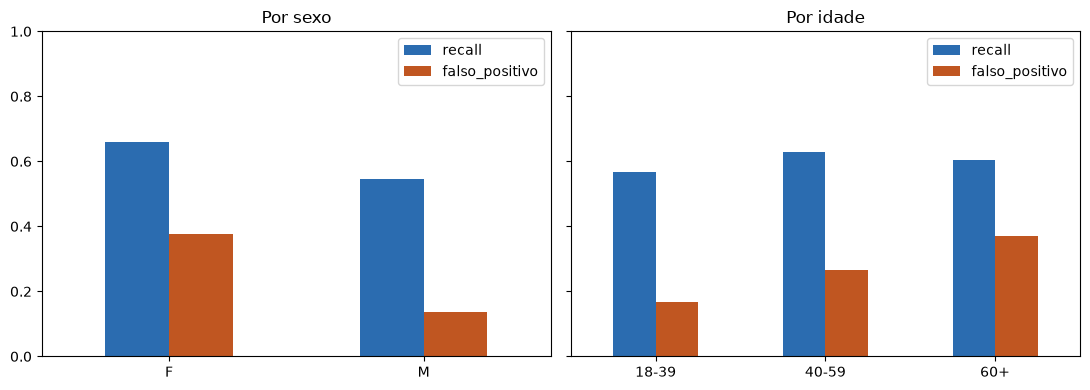

In [5]:
figura, eixos = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eixo, (titulo, metricas_dos_grupos) in zip(eixos, [("Por sexo", por_sexo), ("Por idade", por_idade)]):
    metricas_dos_grupos[["recall", "falso_positivo"]].plot.bar(ax=eixo, rot=0, color=["#2b6cb0", "#c05621"])
    eixo.set(title=titulo, ylim=(0, 1), xlabel="")
figura.tight_layout()
figura.savefig("fairness.png", dpi=120)
plt.show()